# Supplementary Figure S8. Pairs that DSSR reports but RUBRIC does not classify

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageOps

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data").is_dir() and (base / "notebooks").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
RENDERS = ROOT / "data" / "pymol" / "renders"

def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 600, "savefig.bbox": "tight",
    "savefig.pad_inches": 0.08,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 7, "pdf.fonttype": 42, "ps.fonttype": 42,
})

# key: (pdb, left nucleotide, right nucleotide, dashes, title, class)
# class is DSSR's
# nucleotide = (chain, resi, resn); dash = (left atom, right atom)
EXAMPLES = {
    "8D29_cWW": ("8D29", ("R", 26, "G"), ("R", 9, "C"),
                 [("N1", "O2")], "8D29 G26-C9", "cWW"),
    "2Z75_cHS": ("2Z75", ("B", 37, "G"), ("A", 1, "G"),
                 [("N7", "O2'")], "2Z75 G37-G1", "cHS"),
    "3D2V_cSS": ("3D2V", ("A", 29, "A"), ("A", 36, "C"),
                 [("O2'", "O2'"), ("N3", "O2'")], "3D2V A29-C36", "cSS"),
}

## PyMOL renders
The renders are made by `scripts/pymol_figures/render_pair_examples.py S8` (needs PyMOL and `data/structures`), which reads the `EXAMPLES` table above. Each example is saved as `data/pymol/renders/<key>.png`, with the H-bond lengths and label positions in `<key>_meta.json` and the session in `data/pymol/sessions/<key>.pse`. This notebook only reads these files.

## Shared panel helpers
All renders share one print scale, set so the widest pair fills a third of the 6.73 in page. One label under each pair, 7 pt, as in Figure 3B.

In [2]:
PAD = 4
LABEL_H = 0.17               # inches reserved under each render for its label
# distance label offset from the dash centre, render px; one per dash
LABEL_OFF = {"8D29_cWW": [(0, -42)], "2Z75_cHS": [(43, -58)], "3D2V_cSS": [(61, 72), (74, -65)]}

def crop(key, thresh=246):
    im = Image.open(RENDERS / f"{key}.png").convert("RGB")
    l, t, r, b = ImageOps.grayscale(im).point(lambda v: 255 if v < thresh else 0).getbbox()
    box = (l - PAD, t - PAD, r + PAD, b + PAD)
    return im.crop(box), box

FIG_W, GUTTER = 6.73, 0.10   # page width; space between neighbouring renders
NCOL = 3                     # panels per row in the combined figure
# one scale for all panels, set so the widest render fills its third of the page
IN_PER_PX = (FIG_W / NCOL - GUTTER) / max(crop(k)[0].width for k in EXAMPLES)

def render_size(key):
    im, _ = crop(key)
    return im.width * IN_PER_PX, im.height * IN_PER_PX

def label(key):
    pdb, nt1, nt2, dashes, title, lw = EXAMPLES[key]
    return f"{title} ({lw})"

def draw_render(ax, key):
    """The cropped render plus the H-bond lengths, in render pixels."""
    pdb, nt1, nt2, dashes, title, lw = EXAMPLES[key]
    meta = json.loads((RENDERS / f"{key}_meta.json").read_text())
    im, (l, t, _, _) = crop(key)
    ax.imshow(im); ax.set_axis_off()
    for i, (dx, dy) in enumerate(LABEL_OFF[key]):
        x, y, _ = meta["px"][f"d{i}"]
        ax.text(x - l + dx, y - t + dy, f"{meta['dist'][f'd{i}']:.2f} Å", ha="center",
                va="center", fontsize=7, color="0.3")

def place(fig, key, cx, img_top, row_img_h):
    """Render centred on cx, vertically centred in a row of height row_img_h; label below."""
    W, H = fig.get_size_inches()
    w, h = render_size(key)
    y0 = img_top + (row_img_h - h) / 2
    draw_render(fig.add_axes([(cx - w / 2) / W, 1 - (y0 + h) / H, w / W, h / H]), key)
    fig.text(cx / W, 1 - (img_top + row_img_h + 0.04) / H, label(key), ha="center", va="top",
             fontsize=7, color="black")

def panel_figure(key):
    w, h = render_size(key)
    fig = plt.figure(figsize=(w + 0.1, h + LABEL_H + 0.1))
    place(fig, key, (w + 0.1) / 2, 0.05, h)
    return fig

## Panel A
cWW, 8D29 G26-C9: bases pulled apart; DSSR's only contact is 3.94 Å

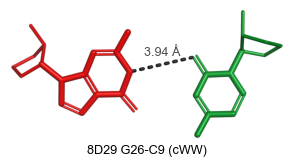

In [3]:
fig = panel_figure("8D29_cWW")
save(fig, "figures/supplemental/figS8_A_8D29_cWW.png")
plt.show()

## Panel B
cHS, 2Z75 G37-G1: ribose-to-base hydrogen bond only

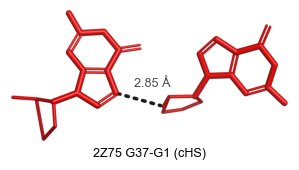

In [4]:
fig = panel_figure("2Z75_cHS")
save(fig, "figures/supplemental/figS8_B_2Z75_cHS.png")
plt.show()

## Panel C
cSS, 3D2V A29-C36: ribose-ribose and base-ribose hydrogen bonds only

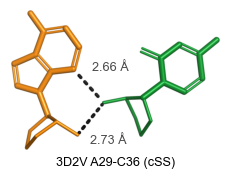

In [5]:
fig = panel_figure("3D2V_cSS")
save(fig, "figures/supplemental/figS8_C_3D2V_cSS.png")
plt.show()

## Combined figure
Three equal columns across the 6.73 in page width; renders share one height so the labels line up.

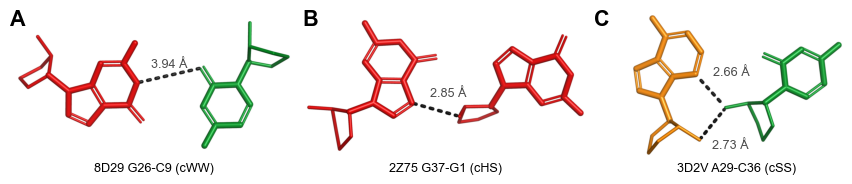

In [6]:
TOP, ROW_GAP = 0.06, 0.14
col_w = FIG_W / NCOL
keys = list(EXAMPLES)
rows = [keys[i:i + NCOL] for i in range(0, len(keys), NCOL)]
row_h = [max(render_size(k)[1] for k in row) for row in rows]
fig = plt.figure(figsize=(FIG_W, TOP + sum(row_h) + len(rows) * LABEL_H + (len(rows) - 1) * ROW_GAP))
H = fig.get_size_inches()[1]
top = TOP
for r, row in enumerate(rows):
    for c, key in enumerate(row):
        place(fig, key, (c + 0.5) * col_w, top, row_h[r])
        fig.text((c * col_w + 0.02) / FIG_W, 1 - (top - 0.04) / H, "ABCDEF"[r * NCOL + c],
                 fontsize=12, fontweight="bold", ha="left", va="top")
    top += row_h[r] + LABEL_H + ROW_GAP
save(fig, "figures/supplemental/figS8.png")
plt.show()